# 04 · Denoising Diffusion Models: Stable Training, Sharp Samples

## Overview

By the end of Notebook 03 we had two families with complementary problems:

* **VAEs** train stably with a clear objective (the ELBO), but their samples are **over-smoothed**.
* **GANs** produce sharper samples, but training is **fragile**, modes get **dropped**, and there is **no likelihood**.

Diffusion models (Sohl-Dickstein *et al.*, 2015; Ho, Jain & Abbeel, 2020) take a different route. Generating a whole frame in one shot is hard. **Removing a little noise** from a noisy frame is easy. A diffusion model learns that small step and repeats it hundreds of times, turning pure noise into data.

Its training objective is plain regression ("predict the noise that was added"), so it is as stable as training a classifier. The resulting sampler is a likelihood-based model whose samples are not blurred. Diffusion has since become the basis of image generators and of protein design tools such as **RFdiffusion** and the structure module of **AlphaFold 3** (Notebook 06).

## Learning objectives

1. Describe the forward (noising) process and derive the closed form $q(x_t \mid x_0)$.
2. Implement the DDPM training objective and ancestral sampling from scratch, and see why the prediction target ($\epsilon$ vs $v$) matters.
3. Add **classifier-free guidance** for conditional generation and explore the quality/diversity trade-off.
4. Use **DDIM** to sample 20× faster with a deterministic sampler.
5. Compare VAE, GAN and diffusion samples on the shared scorecard.

**Runtime:** about 6 minutes on a laptop CPU.

In [1]:
import sys, time, math, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
sys.path.insert(0, ".")
from ppi_dl.data import load_ppi, set_seed
from ppi_dl.metrics import Scorecard, load_scorecards
from ppi_dl.plotting import plot_pca_overlay, plot_feature_distributions

data = load_ppi("block")
Xtr, ytr = torch.tensor(data.X_train), torch.tensor(data.y_train)
D_IN, N = data.n_features, len(Xtr)
sc = Scorecard(data)
sc.reference()
iface = data.interface
print(data.summary())

split=block: train (3200, 4886), test (800, 4886), train class counts [1600, 1600], test class counts [400, 400]


## 1. The forward process: destroying a frame, one step at a time

Pick a **noise schedule** $\beta_1, \dots, \beta_T$ (small numbers, here growing linearly from $10^{-4}$ to $0.02$ over $T = 1000$ steps). Each forward step adds a little Gaussian noise and shrinks the signal slightly:
$$ q(x_t \mid x_{t-1}) = \mathcal{N}\big(\sqrt{1-\beta_t}\, x_{t-1},\; \beta_t I\big) $$

Composing Gaussians gives a closed form that lets us jump to any step directly. With $\alpha_t = 1-\beta_t$ and $\bar\alpha_t = \prod_{s\le t}\alpha_s$:
$$ x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\;\epsilon, \qquad \epsilon \sim \mathcal{N}(0, I). $$

As $t \to T$, $\bar\alpha_t \to 0$, so $x_T$ is essentially pure noise, whatever $x_0$ was.

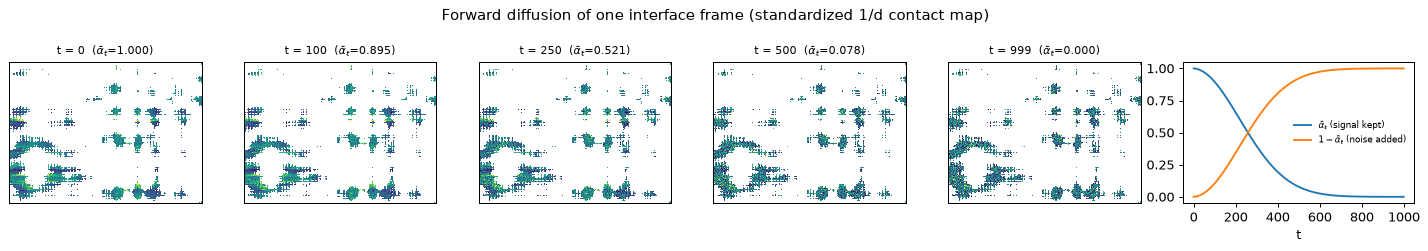

In [2]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T)
alphas = 1.0 - betas
abar = torch.cumprod(alphas, 0)

def q_sample(x0, t, eps):
    ab = abar[t].view(-1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

x0 = Xtr[:1]
steps_to_show = [0, 100, 250, 500, 999]
fig, axes = plt.subplots(1, len(steps_to_show) + 1, figsize=(16, 2.8),
                         gridspec_kw={"width_ratios": [1] * len(steps_to_show) + [1.2]})
set_seed(0); eps = torch.randn_like(x0)
for ax, t in zip(axes, steps_to_show):
    xt = q_sample(x0, torch.tensor([t]), eps).numpy()
    M, mask = iface.to_pair_matrix(xt, fill=np.nan)
    ax.imshow(M[0].T, aspect="auto", cmap="viridis", vmin=-2, vmax=3, interpolation="nearest")
    ax.set_title(f"t = {t}  ($\\bar\\alpha_t$={abar[t]:.3f})", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
axes[-1].plot(abar.numpy(), label=r"$\bar\alpha_t$ (signal kept)")
axes[-1].plot((1 - abar).numpy(), label=r"$1-\bar\alpha_t$ (noise added)")
axes[-1].set_xlabel("t"); axes[-1].legend(fontsize=7, frameon=False)
fig.suptitle("Forward diffusion of one interface frame (standardized 1/d contact map)")
fig.tight_layout(); plt.show()

## 2. The reverse process and the training objective

To generate, we run the chain **backwards**: start from $x_T \sim \mathcal{N}(0, I)$ and repeatedly sample $x_{t-1}$ given $x_t$. For small $\beta_t$ each reverse step is also approximately Gaussian. Its mean depends on the unknown clean frame, so we train a network to estimate it.

Ho *et al.* (2020) showed that a reweighted ELBO reduces to a remarkably simple loss: **predict the noise**.
$$ \mathcal{L}_{\text{simple}} = \mathbb{E}_{x_0,\, t,\, \epsilon}\Big[\big\lVert \epsilon - \epsilon_\theta\big(\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\; t\big)\big\rVert^2\Big] $$

Compare this with the GAN: there is no adversary and no minimax. It is a regression problem, and its loss decreases smoothly.

### The denoiser network

$\epsilon_\theta(x_t, t, c)$ receives three inputs:

* the noisy frame $x_t$ (4,886 numbers);
* the time step $t$, encoded with **sinusoidal embeddings** (the same trick transformers use for positions, Notebook 05), so the network knows how much noise to expect;
* a label $c \in \{\text{SARS-CoV}, \text{SARS-CoV-2}, \varnothing\}$. The extra "null" label $\varnothing$ enables classifier-free guidance (Section 4).

We use a residual MLP with layer normalization. We also keep an **exponential moving average (EMA)** of the weights for sampling, a standard trick that noticeably improves diffusion samples.

In [3]:
def timestep_embedding(t, dim=128):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half) / half)
    a = t[:, None].float() * freqs[None]
    return torch.cat([a.sin(), a.cos()], dim=1)

NULL = 2   # label index meaning "no label"

class ResBlock(nn.Module):
    def __init__(self, h):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(h), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, h))
    def forward(self, x):
        return x + self.net(x)

class MLPDenoiser(nn.Module):
    def __init__(self, d, hidden=512, n_blocks=3):
        super().__init__()
        self.inp = nn.Linear(d, hidden)
        self.t_mlp = nn.Sequential(nn.Linear(128, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.c_emb = nn.Embedding(3, hidden)
        self.blocks = nn.Sequential(*[ResBlock(hidden) for _ in range(n_blocks)])
        self.out = nn.Sequential(nn.LayerNorm(hidden), nn.Linear(hidden, d))
    def forward(self, x, t, c):
        h = self.inp(x) + self.t_mlp(timestep_embedding(t)) + self.c_emb(c)
        return self.out(self.blocks(h))

def train_diffusion(model, epochs=80, bs=64, lr=1e-3, p_uncond=0.1, ema_decay=0.999, abar=abar,
                    target="v", log_every=20):
    """target="eps": predict the added noise (Ho et al. 2020).
       target="v"  : predict v = sqrt(abar) * eps - sqrt(1 - abar) * x0 (Salimans & Ho 2022)."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    ema = copy.deepcopy(model).eval()
    losses = []
    for ep in range(epochs):
        perm, run = torch.randperm(N), []
        for i in range(0, N, bs):
            idx = perm[i:i + bs]
            x0, c = Xtr[idx], ytr[idx].clone()
            c[torch.rand(len(c)) < p_uncond] = NULL                 # label dropout for CFG
            t = torch.randint(0, T, (len(x0),))
            eps = torch.randn_like(x0)
            ab = abar[t].view(-1, 1)
            xt = ab.sqrt() * x0 + (1 - ab).sqrt() * eps
            goal = eps if target == "eps" else ab.sqrt() * eps - (1 - ab).sqrt() * x0
            loss = F.mse_loss(model(xt, t, c), goal)
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                for pe, p in zip(ema.parameters(), model.parameters()):
                    pe.mul_(ema_decay).add_(p, alpha=1 - ema_decay)
            run.append(loss.item())
        sched.step(); losses.append(np.mean(run))
        if ep % log_every == 0:
            print(f"epoch {ep:3d}  loss {losses[-1]:.4f}")
    return ema, losses

set_seed(0)
net_eps = MLPDenoiser(D_IN)
print("denoiser parameters:", sum(p.numel() for p in net_eps.parameters()))
t0 = time.time()
ema_eps, losses_eps = train_diffusion(net_eps, epochs=15, target="eps", log_every=5)
print(f"trained in {time.time()-t0:.0f}s")
print(f"final loss {losses_eps[-1]:.3f}   vs   1 - 512/4886 = {1 - 512 / D_IN:.3f}")

denoiser parameters: 6918934
epoch   0  loss 1.0386
epoch   5  loss 0.9611
epoch  10  loss 0.9230
trained in 16s
final loss 0.916   vs   1 - 512/4886 = 0.895


### A first attempt fails, and the reason is instructive

The loss stalls near **0.90**, and the number is no coincidence: it is $1 - 512/4886$.

At high noise levels, $x_t$ is almost pure noise, so the best guess for $\epsilon$ is essentially $x_t$ itself, a full-rank 4,886-dimensional random vector. Our denoiser squeezes its input through a **512-unit** hidden layer, so it can reproduce at most a 512-dimensional slice of that vector. The rest of the noise (about 90% of its variance) is lost, whatever we do. Image diffusion models avoid this because their U-Nets have skip connections that can copy the input straight to the output. A narrow MLP cannot.

Worse, sampling must convert the noise estimate into a clean-frame estimate,
$\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon)/\sqrt{\bar\alpha_t}$, and at $t \approx T$ the factor $1/\sqrt{\bar\alpha_t} \approx 150$ amplifies every error. Section 5 shows what that does to samples.

**The fix: predict a different target.** Salimans & Ho (2022) proposed predicting the "velocity"
$$ v = \sqrt{\bar\alpha_t}\,\epsilon - \sqrt{1-\bar\alpha_t}\,x_0, \qquad\text{so that}\qquad \hat x_0 = \sqrt{\bar\alpha_t}\,x_t - \sqrt{1-\bar\alpha_t}\,\hat v,\quad \hat\epsilon = \sqrt{1-\bar\alpha_t}\,x_t + \sqrt{\bar\alpha_t}\,\hat v. $$
The "copy $x_t$" part is now handled **analytically** by the $\sqrt{\cdot}\,x_t$ terms. At high noise, $v \approx -x_0$, which lies near the low-dimensional data manifold (Notebook 02: 50 principal components carry 86% of the variance), so a 512-unit bottleneck can represent it. The training objective is still plain regression. Only the target changed.

epoch   0  loss 0.8557
epoch  20  loss 0.6240
epoch  40  loss 0.5918
epoch  60  loss 0.5870
trained in 74s


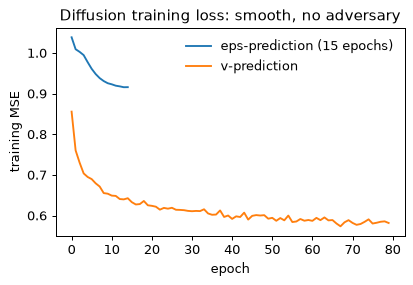

In [4]:
set_seed(0)
net = MLPDenoiser(D_IN)
t0 = time.time()
ema, losses = train_diffusion(net, epochs=80, target="v")
print(f"trained in {time.time()-t0:.0f}s")
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(losses_eps, label="eps-prediction (15 epochs)"); ax.plot(losses, label="v-prediction")
ax.set_xlabel("epoch"); ax.set_ylabel("training MSE"); ax.legend(frameon=False)
ax.set_title("Diffusion training loss: smooth, no adversary"); plt.show()

## 3. Sampling: ancestral (DDPM) sampling

Given the predicted noise, the mean of the reverse step is
$$ \mu_\theta(x_t, t) = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t, t)\Big), \qquad x_{t-1} = \mu_\theta + \sqrt{\beta_t}\, z,\; z\sim\mathcal{N}(0, I). $$

This takes **1,000 network evaluations per sample**, compared with one for a VAE or GAN. We record a few intermediate states to watch a frame emerge from noise.

In [5]:
@torch.no_grad()
def guided_eps(model, x, t, c, w, target="v"):
    """Network output (with classifier-free guidance, Section 4) converted to a noise estimate."""
    tt = torch.full((len(x),), t, dtype=torch.long)
    out = model(x, tt, c)
    if w != 0:
        out = (1 + w) * out - w * model(x, tt, torch.full_like(c, NULL))
    if target == "eps":
        return out
    ab = abar[t]
    return (1 - ab).sqrt() * x + ab.sqrt() * out       # eps from v

@torch.no_grad()
def sample_ddpm(model, c, w=0.0, record=()):
    x = torch.randn(len(c), D_IN); traj = {}
    for t in reversed(range(T)):
        e = guided_eps(model, x, t, c, w)
        x = (x - betas[t] / (1 - abar[t]).sqrt() * e) / alphas[t].sqrt()
        if t > 0:
            x = x + betas[t].sqrt() * torch.randn_like(x)
        if t in record:
            traj[t] = x.clone()
    return x.numpy(), traj

set_seed(0)
n_gen = len(data.X_test)
t0 = time.time()
s_uncond, traj = sample_ddpm(ema, torch.full((n_gen,), NULL), record=(999, 750, 500, 250, 100, 0))
print(f"{n_gen} samples x {T} steps in {time.time()-t0:.0f}s")
sc.evaluate(s_uncond, name="DDPM (unconditional)")
sc.table()

800 samples x 1000 steps in 57s


,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.0,NaN
DDPM (unconditional),1.361,0.013,0.566,0.458,0.879,NaN,0.982


PC1-2 spread: real held-out 31.0, pure Gaussian noise 1.0


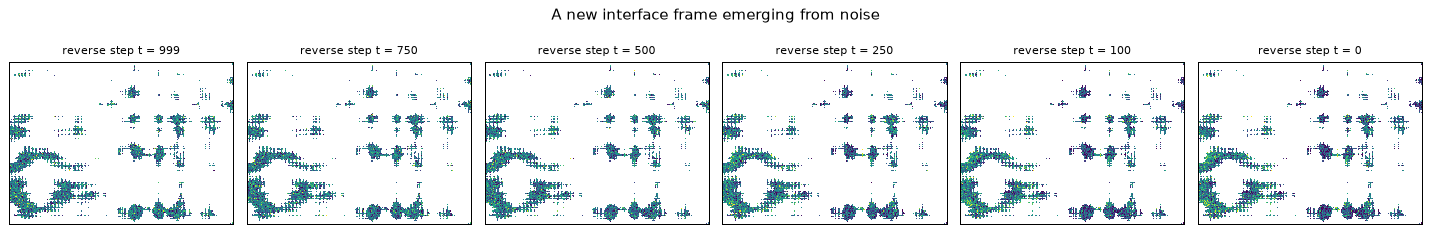

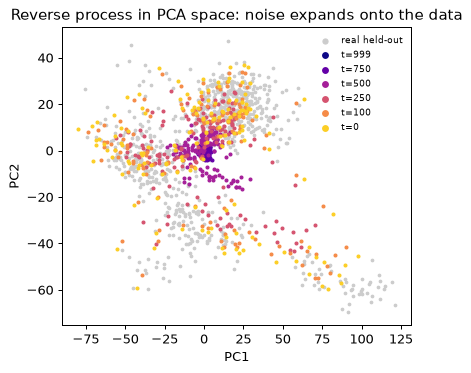

In [6]:
fig, axes = plt.subplots(1, 6, figsize=(16, 2.6))
for ax, t in zip(axes, sorted(traj, reverse=True)):
    M, _ = iface.to_pair_matrix(traj[t][:1].numpy(), fill=np.nan)
    ax.imshow(M[0].T, aspect="auto", cmap="viridis", vmin=-2, vmax=3, interpolation="nearest")
    ax.set_title(f"reverse step t = {t}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("A new interface frame emerging from noise"); fig.tight_layout(); plt.show()

Zs = {t: sc.pca.transform(traj[t][:150].numpy()) for t in traj}
fig, ax = plt.subplots(figsize=(5, 4.3))
ax.scatter(*sc.Zte[:, :2].T, s=4, color="0.8", label="real held-out")
for t, col in zip(sorted(traj, reverse=True), plt.cm.plasma(np.linspace(0, 0.9, len(traj)))):
    ax.scatter(*Zs[t][:, :2].T, s=5, color=col, label=f"t={t}")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=7, frameon=False, markerscale=2)
ax.set_title("Reverse process in PCA space: noise expands onto the data"); plt.show()
print("PC1-2 spread: real held-out %.1f, pure Gaussian noise %.1f"
      % (sc.Zte[:, :2].std(), sc.pca.transform(np.random.default_rng(0).standard_normal(
          (400, D_IN)).astype(np.float32))[:, :2].std()))

The second panel is worth a moment's thought, because the direction is the opposite of
what "denoising" suggests. The principal components were fitted to **real** frames, whose
spread along PC1–PC2 is large. Isotropic Gaussian noise has unit variance in *every*
direction, so projected onto those same components it collapses to a tight blob at the
origin. The reverse process therefore starts concentrated and **expands** outward until the
samples match the real spread. What contracts is the set of *directions* the samples occupy:
from all 4,886 equally, to the handful that real interface motions actually use.

## 4. Classifier-free guidance

To generate a requested variant, we trained the denoiser to accept a label, and randomly replaced it with "null" 10% of the time. At sampling time, **classifier-free guidance** (Ho & Salimans, 2022) extrapolates away from the unconditional prediction:
$$ \tilde\epsilon = (1 + w)\,\epsilon_\theta(x_t, t, c) - w\,\epsilon_\theta(x_t, t, \varnothing). $$

* $w = 0$: plain conditional sampling.
* $w > 0$: push samples to be *more typical* of class $c$. This usually raises fidelity to the label and precision, at the cost of diversity.

(With v-prediction we apply the same formula to $\hat v$; because $\hat\epsilon$ is linear in $\hat v$, this is identical to guiding $\hat\epsilon$.)

This one knob is behind the "prompt strength" setting in text-to-image tools. In protein design, guidance steers generation toward a desired property.

Ancestral sampling with guidance costs 2,000 network calls per sample, so for the sweep we switch to a faster sampler.

## 5. DDIM: same model, 20× fewer steps

Song, Meng & Ermon (2021) noticed that the DDPM training objective does not pin down the sampling chain. A **deterministic** reverse process that skips steps gives the same marginals. At each chosen step, estimate the clean frame, then jump straight to the next, noisier, step:
$$ \hat x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\tilde\epsilon}{\sqrt{\bar\alpha_t}}, \qquad x_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat x_0 + \sqrt{1-\bar\alpha_{t'}}\,\tilde\epsilon. $$

No retraining is needed, only a different sampler.

In [7]:
@torch.no_grad()
def sample_ddim(model, c, w=0.0, n_steps=50, target="v"):
    ts = torch.linspace(T - 1, 0, n_steps).long()
    x = torch.randn(len(c), D_IN)
    for i, t in enumerate(ts):
        e = guided_eps(model, x, int(t), c, w, target)
        x0_hat = (x - (1 - abar[t]).sqrt() * e) / abar[t].sqrt()
        ab_next = abar[ts[i + 1]] if i + 1 < n_steps else torch.tensor(1.0)
        x = ab_next.sqrt() * x0_hat + (1 - ab_next).sqrt() * e
    return x.numpy()

# the failed epsilon-model from Section 2, sampled with the same sampler
set_seed(0)
s_eps = sample_ddim(ema_eps, torch.full((n_gen,), NULL), target="eps")
sc.evaluate(s_eps, name="DDIM-50, eps-prediction (failed, 15 ep)")

y_req = torch.tensor(data.y_test)
set_seed(0); t0 = time.time()
s_ddim_uncond = sample_ddim(ema, torch.full((n_gen,), NULL))
print(f"DDIM, 50 steps: {time.time()-t0:.1f}s")
sc.evaluate(s_ddim_uncond, name="DDIM-50 (unconditional)")

guidance = []
for w in [0.0, 1.0, 2.0, 4.0]:
    set_seed(0)
    s = sample_ddim(ema, y_req, w=w)
    guidance.append(sc.evaluate(s, data.y_test, name=f"DDIM-50, guidance w={w}", store=(w == 1.0)) | {"w": w})
    if w == 1.0:
        s_cfg = s
guidance = pd.DataFrame(guidance).set_index("w")
guidance[["judge_acc", "precision", "coverage", "std_ratio", "mmd"]].round(3)

DDIM, 50 steps: 1.2s


,judge_acc,precision,coverage,std_ratio,mmd
w,,,,,
0.0,0.990,0.649,0.545,1.273,0.010
1.0,0.998,0.682,0.532,1.305,0.013
2.0,0.999,0.632,0.472,1.330,0.020
4.0,0.999,0.521,0.321,1.379,0.040


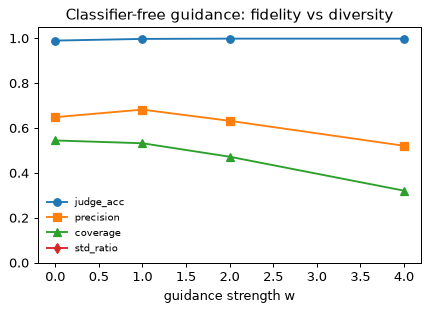

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for m, mk in [("judge_acc", "o"), ("precision", "s"), ("coverage", "^"), ("std_ratio", "d")]:
    ax.plot(guidance.index, guidance[m], marker=mk, label=m)
ax.set_xlabel("guidance strength w"); ax.set_ylim(0, 1.05); ax.legend(frameon=False, fontsize=8)
ax.set_title("Classifier-free guidance: fidelity vs diversity"); plt.show()

## 6. Three generative families, one scorecard

In [9]:
prev = load_scorecards()
keep = {"02_VAE": ["PCA-50 Gaussian (linear)", "VAE (k=16, beta=1)", "CVAE (k=16)"],
        "03_GAN": ["vanilla GAN", "WGAN-GP", "cWGAN-GP (projection)"]}
rows = [prev[(prev.notebook == nb) & prev.model.isin(ms)] for nb, ms in keep.items()]
prev_tab = pd.concat(rows).set_index("model").drop(columns="notebook")
compare = pd.concat([sc.table().loc[["real (train frames)"]], prev_tab, sc.table().drop(index="real (train frames)")])
calls = {"VAE (k=16, beta=1)": 1, "CVAE (k=16)": 1, "vanilla GAN": 1, "WGAN-GP": 1,
         "cWGAN-GP (projection)": 1, "DDPM (unconditional)": 1000, "DDIM-50 (unconditional)": 50,
         "DDIM-50, guidance w=1.0": 100}
compare = compare.drop(index=["DDIM-50, eps-prediction (failed, 15 ep)"])  # off the scale; see Section 2
compare["net calls / sample"] = [calls.get(m, np.nan) for m in compare.index]
compare.round(3)

,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio,net calls / sample
model,,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.000,NaN,NaN
PCA-50 Gaussian (linear),1.000,0.015,0.082,0.062,0.956,NaN,1.681,NaN
"VAE (k=16, beta=1)",0.517,0.077,0.499,0.278,0.982,NaN,1.193,1.0
CVAE (k=16),0.571,0.060,0.660,0.336,0.967,1.000,1.079,1.0
vanilla GAN,0.564,0.170,0.840,0.241,0.980,NaN,0.884,1.0
WGAN-GP,0.784,0.023,0.266,0.136,1.000,NaN,1.442,1.0
cWGAN-GP (projection),0.768,0.020,0.346,0.205,0.995,0.999,1.339,1.0
DDPM (unconditional),1.361,0.013,0.566,0.458,0.879,NaN,0.982,1000.0
DDIM-50 (unconditional),1.280,0.011,0.590,0.515,0.871,NaN,0.987,50.0


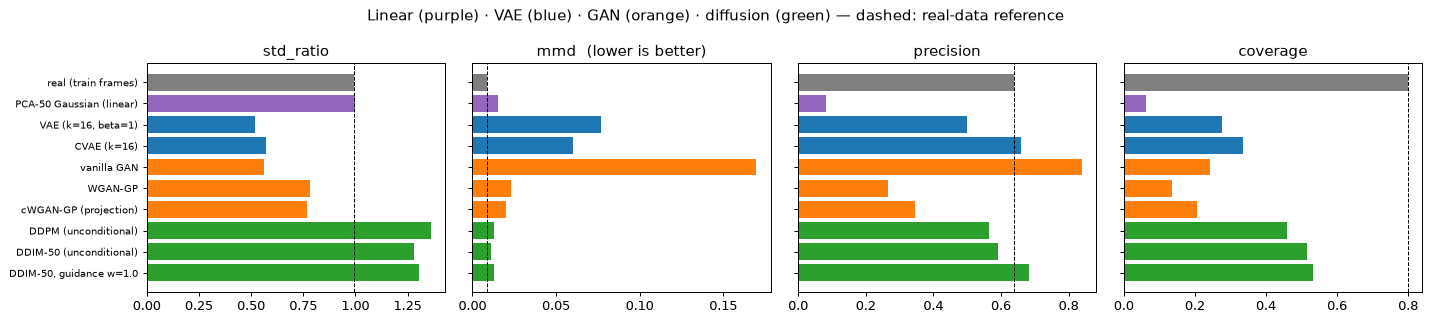

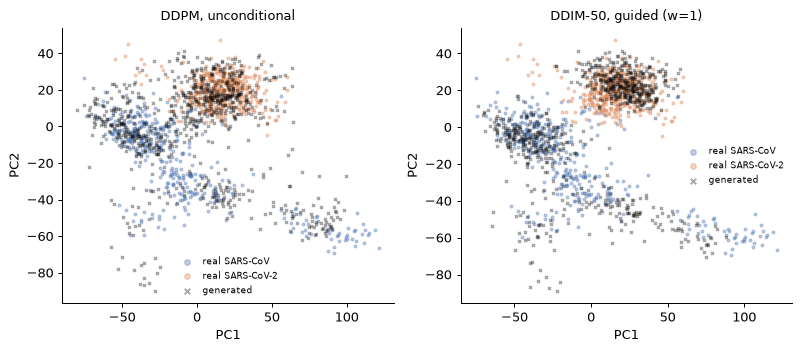

In [10]:
metrics = ["std_ratio", "mmd", "precision", "coverage"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
fam = lambda m: "tab:gray" if m.startswith("real") else ("tab:green" if "DD" in m else
      ("tab:orange" if "GAN" in m else ("tab:blue" if "VAE" in m else "tab:purple")))
for ax, m in zip(axes, metrics):
    v = compare[m]
    ax.barh(range(len(v)), v.values, color=[fam(i) for i in v.index])
    ax.axvline(compare.loc["real (train frames)", m], color="k", ls="--", lw=0.8)
    ax.set_yticks(range(len(v))); ax.set_yticklabels(v.index if m == metrics[0] else [], fontsize=8)
    ax.set_title(m + ("  (lower is better)" if m == "mmd" else "")); ax.invert_yaxis()
fig.suptitle("Linear (purple) · VAE (blue) · GAN (orange) · diffusion (green) — dashed: real-data reference")
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_pca_overlay(sc, s_uncond, title="DDPM, unconditional", ax=axes[0])
plot_pca_overlay(sc, s_cfg, title="DDIM-50, guided (w=1)", ax=axes[1])
fig.tight_layout(); plt.show()

**Reading the comparison.**

1. **Quality and coverage together.** The v-prediction diffusion model is the first model in the series whose `mmd`, `precision` and classifier two-sample AUC approach the real-data reference. It also has the highest `coverage`, so it avoids both the VAE's over-smoothing and the GANs' mode dropping. Its main blemish is a `std_ratio` somewhat above 1: samples are slightly *over*-dispersed (residual noise that the bottleneck cannot remove at the last steps).
2. **Conditioning.** Guidance at moderate $w$ hits the requested variant (`judge_acc`) while keeping most of the diversity. Large $w$ trades coverage for typicality, which is the classic guidance trade-off.
3. **Cost.** Diffusion pays with many network evaluations per sample. DDIM reduces that cost but does not remove it, which is why fast samplers (DPM-Solver, consistency models, **flow matching**) remain an active research area.
4. **Parameterization matters.** The same network, trained to predict $\epsilon$, failed completely (Section 2). Choosing what the network predicts (ε, $x_0$ or $v$) is a design decision, not a detail.

Also check `nn_ratio`: a powerful model trained on only 3,200 frames could simply **memorize** them. A ratio well below 1 would mean samples sit closer to training frames than genuinely new real frames do.

## 7. What every model so far ignores

The VAE, GAN and diffusion models above all used **multi-layer perceptrons on a flat 4,886-vector**. They have no idea that:

* feature 17 and feature 18 involve the **same ACE2 residue**;
* the interface is a **set of residues** with identities and partners, not a list of numbers;
* the same RBD position appears in many pairs.

You can verify this. Shuffle the feature order consistently in train and test, and an MLP's results are **unchanged**: it treats the interface as an arbitrary list. The first layer alone holds $4{,}886 \times 512 \approx 2.5$M weights, with no sharing between residues.

Proteins have structure: residues, pairs and neighbourhoods. The architecture designed to reason about **which elements of a set should attend to which others** is the transformer. That is **Notebook 05**.

## Challenge Problem 1: How few steps can DDIM take?

Using the trained `ema` model, generate 800 unconditional samples with DDIM at `n_steps` ∈ {5, 10, 25, 100}. Report `precision`, `coverage`, `mmd` and wall-clock time for each. Where does quality start to degrade?

In [11]:
# Start your code here

### Challenge Problem 1 Solution

In [12]:
rows = []
for k in [5, 10, 25, 100]:
    set_seed(0); t0 = time.time()
    s = sample_ddim(ema, torch.full((n_gen,), NULL), n_steps=k)
    dt = time.time() - t0
    r = sc.evaluate(s, name=f"DDIM-{k}", store=False)
    rows.append({"steps": k, "seconds": round(dt, 1), **{m: r[m] for m in ["precision", "coverage", "mmd", "std_ratio"]}})
pd.DataFrame(rows).set_index("steps").round(3)

,seconds,precision,coverage,mmd,std_ratio
steps,,,,,
5,0.2,0.690,0.498,0.046,0.860
10,0.3,0.654,0.516,0.021,1.091
25,0.6,0.618,0.520,0.012,1.234
100,2.4,0.590,0.512,0.011,1.304


## Challenge Problem 2: The cosine noise schedule

Nichol & Dhariwal (2021) noticed that the linear schedule destroys information too fast, leaving many late steps that are almost pure noise. They proposed $\bar\alpha_t = \cos^2\!\big(\tfrac{t/T + s}{1+s}\cdot\tfrac{\pi}{2}\big)$ with $s = 0.008$.

1. Plot $\bar\alpha_t$ for both schedules.
2. Train a new denoiser with the cosine schedule for 40 epochs (pass `abar=abar_cos` to `train_diffusion`) and sample it with DDIM-50, after setting the global `abar` used by the sampler. Compare with the linear model trained for the same number of epochs.

In [13]:
# Start your code here

### Challenge Problem 2 Solution

epoch   0  loss 0.8557
epoch   0  loss 0.8688


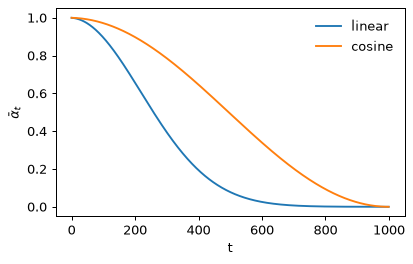

,precision,coverage,mmd,std_ratio
linear,0.6575,0.48,0.016303,1.219759
cosine,0.57375,0.435,0.02676,1.202805


In [14]:
s_off = 0.008
tt = torch.arange(T + 1) / T
f = torch.cos((tt + s_off) / (1 + s_off) * math.pi / 2) ** 2
abar_cos = (f / f[0])[1:].clamp(min=1e-5)
abar_lin = abar.clone()

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(abar_lin.numpy(), label="linear"); ax.plot(abar_cos.numpy(), label="cosine")
ax.set_xlabel("t"); ax.set_ylabel(r"$\bar\alpha_t$"); ax.legend(frameon=False); plt.show()

results = {}
for name, ab in [("linear", abar_lin), ("cosine", abar_cos)]:
    set_seed(0)
    m, _ = train_diffusion(MLPDenoiser(D_IN), epochs=40, abar=ab, log_every=1000)
    abar = ab                                   # the DDIM sampler reads the global schedule
    set_seed(0)
    s = sample_ddim(m, torch.full((n_gen,), NULL))
    results[name] = sc.evaluate(s, name=f"DDIM-50, {name} schedule (40 ep)", store=False)
abar = abar_lin                                 # restore
pd.DataFrame(results).T[["precision", "coverage", "mmd", "std_ratio"]].round(3)

## Save the scorecard

In [15]:
print("saved", sc.save("04_diffusion"))

saved results/scorecard.csv


## Summary

* Diffusion models learn to reverse a fixed noising process. Training is plain regression, which is stable and has no adversary.
* What the network predicts matters: ε-prediction failed with a narrow MLP; v-prediction fixed it by handling the identity part analytically.
* Ancestral sampling takes many small denoising steps. DDIM trades stochasticity for 20× fewer steps with the same trained network.
* Classifier-free guidance turns one network into both a conditional and an unconditional model, with a knob that trades fidelity against diversity.
* Every model so far treats the interface as a flat vector. Exploiting residue structure requires attention (Notebook 05).

## References

* Sohl-Dickstein J. *et al.* (2015) Deep unsupervised learning using nonequilibrium thermodynamics. *ICML*.
* Ho J., Jain A., Abbeel P. (2020) Denoising diffusion probabilistic models. *NeurIPS*.
* Song J., Meng C., Ermon S. (2021) Denoising diffusion implicit models. *ICLR*.
* Song Y. *et al.* (2021) Score-based generative modeling through stochastic differential equations. *ICLR*.
* Nichol A., Dhariwal P. (2021) Improved denoising diffusion probabilistic models. *ICML*.
* Ho J., Salimans T. (2022) Classifier-free diffusion guidance. arXiv:2207.12598.
* Salimans T., Ho J. (2022) Progressive distillation for fast sampling of diffusion models. *ICLR*. (v-prediction)